# SHAP Feature Selection (MLP) — Giảm bỏ sót ung thư


1. Sử dụng chính mô hình `GeneMLP` để tính SHAP values (`shap.DeepExplainer`) nhằm đánh giá độ quan trọng của các gene.
2. Kết hợp với Grid Search optimal K


In [ ]:
import pandas as pd
import numpy as np
import os
import copy
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)
import matplotlib.pyplot as plt
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

CANCER_WEIGHT = 3.0   # Phạt nặng bỏ sót ung thư
TARGET_SN     = 0.95  # Sensitivity tối thiểu mục tiêu
K_LIST        = [10, 20, 30, 40, 50, 75, 100, 150]

print(f"CANCER_WEIGHT = {CANCER_WEIGHT}")
print(f"TARGET_SN     = {TARGET_SN}")


Using device: cuda
CANCER_WEIGHT = 3.0
TARGET_SN     = 0.95


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = "/content/drive/MyDrive/gene"

RESULT_DIR = os.path.join(os.path.dirname(BASE_DIR), "results_mlp_attention_cv")
os.makedirs(RESULT_DIR, exist_ok=True)

X_TRAIN_PATH = os.path.join(BASE_DIR, "X_train_rF_DEG_train_lung.csv")
X_TEST_PATH  = os.path.join(BASE_DIR, "X_test_rF_DEG_train_lung.csv")
Y_TRAIN_PATH = os.path.join(BASE_DIR, "y_train_rF_DEG_train.csv")
Y_TEST_PATH  = os.path.join(BASE_DIR, "y_test_rF_DEG_train.csv")

print("Result dir:", RESULT_DIR)


Mounted at /content/drive
Result dir: /content/drive/MyDrive/results_mlp_attention_cv


## 1. Load & Scale Data


In [ ]:
def clean_X(df): return df.loc[:, ~df.columns.str.contains('^Unnamed')]
def clean_y(df): return df.loc[:, ~df.columns.str.contains('^Unnamed')].iloc[:, -1].astype(int)

X_train_full_raw = clean_X(pd.read_csv(X_TRAIN_PATH, low_memory=False))
X_test_raw       = clean_X(pd.read_csv(X_TEST_PATH,  low_memory=False))
y_train_full     = clean_y(pd.read_csv(Y_TRAIN_PATH, low_memory=False))
y_test           = clean_y(pd.read_csv(Y_TEST_PATH,  low_memory=False))

gene_names = X_train_full_raw.columns.tolist()
n_genes    = len(gene_names)

X_train_s, X_val_s, y_train_s, y_val_s = train_test_split(
    X_train_full_raw, y_train_full,
    test_size=0.2, stratify=y_train_full, random_state=RANDOM_STATE
)
X_train_s = X_train_s.reset_index(drop=True)
X_val_s   = X_val_s.reset_index(drop=True)
y_train_s = y_train_s.reset_index(drop=True)
y_val_s   = y_val_s.reset_index(drop=True)
y_test    = y_test.reset_index(drop=True)
X_test_raw = X_test_raw.reset_index(drop=True)

# StandardScaler
std_sc   = StandardScaler()
X_tr_std = pd.DataFrame(std_sc.fit_transform(X_train_s), columns=gene_names)
X_va_std = pd.DataFrame(std_sc.transform(X_val_s),       columns=gene_names)
X_te_std = pd.DataFrame(std_sc.transform(X_test_raw),    columns=gene_names)

print(f"Train : {X_train_s.shape} | Val : {X_val_s.shape} | Test : {X_test_raw.shape}")


Train : (584, 211) | Val : (146, 211) | Test : (183, 211)


## 2. Model & Helper Functions


In [ ]:
class GeneDataset(Dataset):
    def __init__(self, X, y):
        # X và y đều đã reset_index → an toàn
        self.X = torch.tensor(X.values, dtype=torch.float32)
        self.y = torch.tensor(y.values, dtype=torch.float32)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]


class GeneMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(512, 256),       nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128),       nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 1)
        )
    def forward(self, x): return self.mlp(x).squeeze(-1)


def find_threshold(y_true, y_prob, target_sn=TARGET_SN):
    """Tìm threshold thấp nhất đạt Sn >= target_sn,
    trong đó chọn điểm có Sp cao nhất."""
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    valid = np.where(tpr >= target_sn)[0]
    if len(valid) == 0:
        return float(thresholds[np.argmax(tpr)])
    return float(thresholds[valid[np.argmin(fpr[valid])]])


def train_model(X_tr, y_tr, X_va, y_va, is_grid_search=False):
    bs       = 64 if is_grid_search else 32
    epochs   = 50 if is_grid_search else 100
    patience = 8  if is_grid_search else 15

    tr_loader  = DataLoader(GeneDataset(X_tr, y_tr), batch_size=bs, shuffle=True)
    val_loader = DataLoader(GeneDataset(X_va, y_va), batch_size=bs, shuffle=False)

    torch.manual_seed(RANDOM_STATE)
    model     = GeneMLP(X_tr.shape[1]).to(device)

    # Calculate balanced weight dynamically
    num_positives = y_tr.sum()
    num_negatives = len(y_tr) - num_positives
    balanced_weight = float(num_negatives / num_positives)

    pw        = torch.tensor([balanced_weight], dtype=torch.float32).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

    # --- CHANGED: Track best AUC instead of F2 ---
    best_auc, best_state, wait = -1.0, None, 0

    for epoch in range(epochs):
        # Training Phase
        model.train()
        for X_b, y_b in tr_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)

            optimizer.zero_grad()
            logits = model(X_b).squeeze()
            loss = criterion(logits, y_b)
            loss.backward()
            optimizer.step()

        # Validation Phase
        model.eval()
        val_preds = []
        val_targets = []

        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(device), y_b.to(device)
                logits = model(X_b).squeeze()

                # Apply sigmoid to get probabilities for AUC
                probs = torch.sigmoid(logits)

                # Move to CPU and store for metric calculation
                val_preds.extend(probs.cpu().numpy())
                val_targets.extend(y_b.cpu().numpy())

        # --- CHANGED: Calculate AUC and apply early stopping ---
        current_auc = roc_auc_score(val_targets, val_preds)

        if current_auc > best_auc:
            best_auc = current_auc
            best_state = model.state_dict()
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                # print(f"Early stopping at epoch {epoch}. Best AUC: {best_auc:.4f}")
                break

    # Load the best state before returning
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, best_auc

def compute_metrics(y_true, y_pred, y_prob):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)
    sp = tn / (tn + fp) if (tn + fp) > 0 else 0
    sn = recall_score(y_true, y_pred, zero_division=0)
    return {
        "ACC"             : accuracy_score(y_true, y_pred),
        "Precision"       : precision_score(y_true, y_pred, zero_division=0),
        "Sensitivity/Sn"  : sn,
        "Specificity/Sp"  : sp,
        "F1"              : f1_score(y_true, y_pred, zero_division=0),
        "F2"              : fbeta_score(y_true, y_pred, beta=2.0, zero_division=0),
        "AUC"             : roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0,
        "Balanced Accuracy": (sn + sp) / 2,
        "FN"              : fn,
        "FP"              : fp,
    }


@torch.no_grad()
def get_probs(model, X, y, bs=64):
    model.eval()
    probs, labels = [], []
    for Xb, yb in DataLoader(GeneDataset(X, y), batch_size=bs):
        probs.extend(torch.sigmoid(model(Xb.to(device))).cpu().numpy())
        labels.extend(yb.numpy())
    return np.array(probs), np.array(labels)

## 3. Pre-train MLP & Tính SHAP (DeepExplainer)


In [ ]:
import pandas as pd # Import pandas nếu đầu file chưa có
print("Pre-training MLP on full training set for SHAP...")
shap_model, _ = train_model(X_tr_std, y_train_s, X_va_std, y_val_s, is_grid_search=False)
shap_model.eval()
# =================================================================
# BỌC MODEL LẠI CHO SHAP
# =================================================================
class SHAPWrapper(nn.Module):
    def __init__(self, original_model):
        super().__init__()
        self.model = original_model
    def forward(self, x):
        # Khôi phục lại output về dạng (batch_size, 1) cho SHAP
        return self.model(x).unsqueeze(-1)
# Lấy mẫu background (dùng 100 mẫu bằng KMeans để tăng tốc độ tính DeepExplainer)
X_tr_tensor = torch.tensor(X_tr_std.values, dtype=torch.float32).to(device)
background = shap.kmeans(X_tr_tensor.cpu().numpy(), 100)
background_tensor = torch.tensor(background.data, dtype=torch.float32).to(device)
# Bọc model lại trước khi truyền vào explainer
wrapped_shap_model = SHAPWrapper(shap_model)
# Khởi tạo DeepExplainer với model đã bọc
explainer = shap.DeepExplainer(wrapped_shap_model, background_tensor)
# Tính SHAP values trên tập train
shap_values = explainer.shap_values(X_tr_tensor)
# Đưa shape của SHAP values về ma trận 2D chuẩn (batch_size, num_features)
if isinstance(shap_values, list):
    shap_values = shap_values[0]
if shap_values.ndim == 3 and shap_values.shape[-1] == 1:
    shap_values = shap_values.squeeze(-1)
# Tính trung bình trị tuyệt đối điểm SHAP của mỗi feature
mean_abs_shap = np.abs(shap_values).mean(axis=0)
# =================================================================
# TẠO VÀ IN MA TRẬN ĐỘ QUAN TRỌNG CỦA GEN
# =================================================================
# Tạo DataFrame ánh xạ từng Gen với điểm SHAP của nó
importance_df = pd.DataFrame({
    'Gene': gene_names,
    'SHAP_Importance': mean_abs_shap
})
# Sắp xếp các gen theo độ quan trọng giảm dần
importance_df = importance_df.sort_values(by='SHAP_Importance', ascending=False).reset_index(drop=True)
print("==== MA TRẬN ĐỘ QUAN TRỌNG TỔNG QUÁT (TOP 20 GEN) ====")
print(importance_df.head(20).to_string())
# (Tùy chọn) Lưu ma trận độ quan trọng ra file CSV vào RESULT_DIR để dành viết báo cáo
# importance_df.to_csv(os.path.join(RESULT_DIR, "shap_gene_importance.csv"), index=False)
# =================================================================
# Rank genes theo list (để giữ nguyên logic cho hàm phía dưới của bạn)
ranked_indices = np.argsort(mean_abs_shap)[::-1]
feature_ranks_shap = [gene_names[i] for i in ranked_indices]
def get_dataset_for_k(k):
    cols = feature_ranks_shap[:k]
    return X_tr_std[cols], X_va_std[cols], X_te_std[cols]

Pre-training MLP on full training set for SHAP...
==== MA TRẬN ĐỘ QUAN TRỌNG TỔNG QUÁT (TOP 20 GEN) ====
               Gene  SHAP_Importance
0   ENSG00000251562         0.545949
1   ENSG00000182463         0.524929
2   ENSG00000069535         0.474916
3   ENSG00000133742         0.437140
4   ENSG00000133246         0.432814
5   ENSG00000249307         0.405906
6   ENSG00000163221         0.394045
7   ENSG00000230773         0.387476
8   ENSG00000267243         0.379045
9   ENSG00000163359         0.377577
10  ENSG00000104812         0.372711
11  ENSG00000136167         0.355088
12  ENSG00000145860         0.317535
13  ENSG00000176542         0.313403
14  ENSG00000082805         0.302802
15  ENSG00000081059         0.301360
16  ENSG00000171608         0.298914
17  ENSG00000184613         0.298648
18  ENSG00000054654         0.296959
19  ENSG00000160796         0.289671


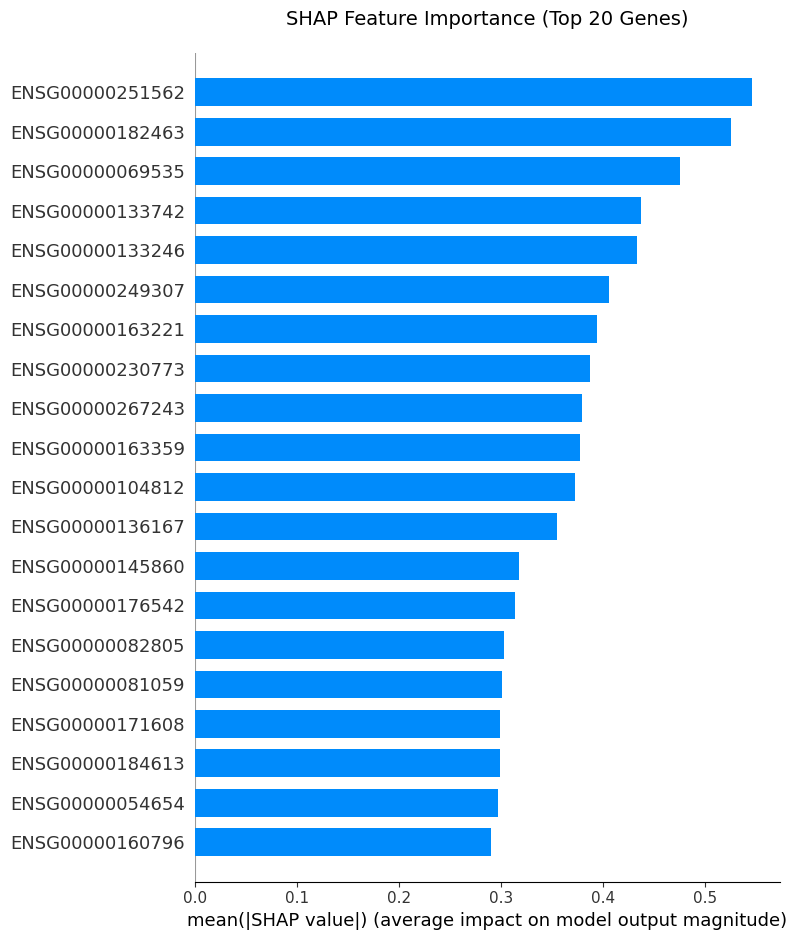

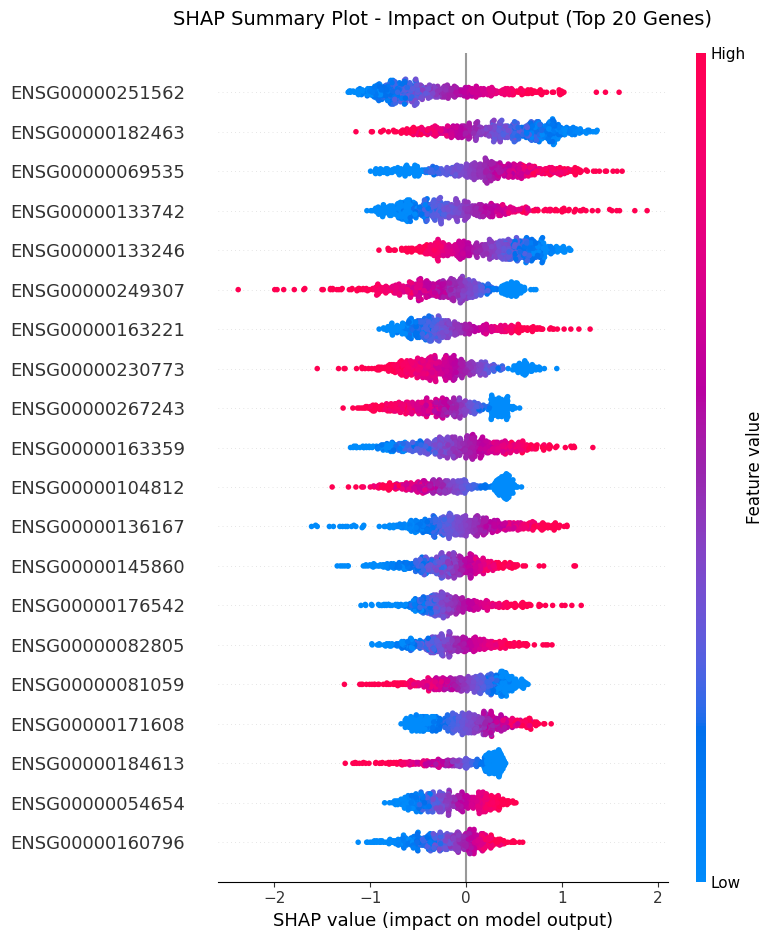

In [ ]:
import matplotlib.pyplot as plt
# Đảm bảo dữ liệu ở định dạng numpy array cho hàm vẽ của shap
shap_vals_np = shap_values  # shape: (n_samples, n_features)
X_tr_np = X_tr_tensor.cpu().numpy()
# =====================================================================
# 1. Biểu đồ thanh (Bar Plot) - Tổng hợp độ quan trọng (Feature Importance)
# =====================================================================
plt.figure(figsize=(10, 8))
plt.title("SHAP Feature Importance (Top 20 Genes)", fontsize=14, pad=20)
# Vẽ bar plot (max_display=20 để chỉ hiển thị 20 gen đứng đầu cho gọn)
shap.summary_plot(shap_vals_np, X_tr_np, feature_names=gene_names, plot_type="bar", max_display=20, show=False)
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "shap_bar_plot.png"), dpi=150)
plt.show()
# =====================================================================
# 2. Biểu đồ dạng giọt nước (Beeswarm / Summary Plot) - Mức độ ảnh hưởng
# =====================================================================
plt.figure(figsize=(10, 8))
plt.title("SHAP Summary Plot - Impact on Output (Top 20 Genes)", fontsize=14, pad=20)
# Vẽ summary plot (hiển thị từng điểm dữ liệu bằng màu sắc đỏ/xanh)
shap.summary_plot(shap_vals_np, X_tr_np, feature_names=gene_names, max_display=20, show=False)
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "shap_summary_plot.png"), dpi=150)
plt.show()

## 4. Grid Search Optimal K dựa trên SHAP


Tiêu chí: Val F2-Score (tại threshold Sn>=0.95)
Quét K: [10, 20, 30, 40, 50, 75, 100, 150]
--------------------------------------------------
  K=10   | Val F2=0.8809
  K=20   | Val F2=0.9164
  K=30   | Val F2=0.9361
  K=40   | Val F2=0.9606
  K=50   | Val F2=0.9612
  K=75   | Val F2=0.9711
  K=100  | Val F2=0.9669
  K=150  | Val F2=0.9596
  => K tối ưu = 75 (Val F2=0.9711)


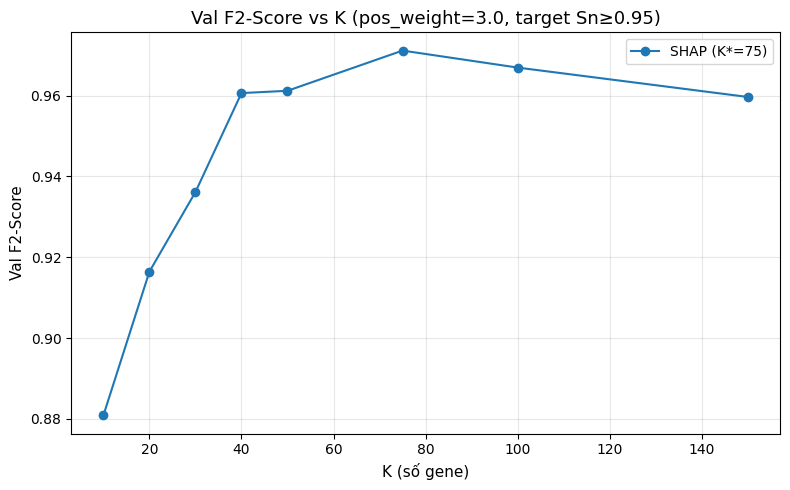

In [ ]:
grid_results = []
best_f2, opt_k = -1, K_LIST[0]

print(f"Tiêu chí: Val F2-Score (tại threshold Sn>={TARGET_SN})")
print(f"Quét K: {K_LIST}")
print("-" * 50)

for k in K_LIST:
    X_tr_k, X_va_k, _ = get_dataset_for_k(k)
    _, val_f2 = train_model(X_tr_k, y_train_s, X_va_k, y_val_s, is_grid_search=True)
    grid_results.append((k, val_f2))
    print(f"  K={k:<4} | Val F2={val_f2:.4f}")
    if val_f2 > best_f2:
        best_f2, opt_k = val_f2, k

print(f"  => K tối ưu = {opt_k} (Val F2={best_f2:.4f})")

# Line plot
ks, f2s = zip(*grid_results)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ks, f2s, marker='o', label=f"SHAP (K*={opt_k})")
ax.set_title(f'Val F2-Score vs K (pos_weight={CANCER_WEIGHT}, target Sn≥{TARGET_SN})', fontsize=13)
ax.set_xlabel('K (số gene)', fontsize=11)
ax.set_ylabel('Val F2-Score', fontsize=11)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "grid_search_shap_f2.png"), dpi=150)
plt.show()


## 5. Đánh giá mô hình cuối cùng với Optimal K


In [ ]:
X_tr_opt, X_va_opt, X_te_opt = get_dataset_for_k(opt_k)

# Train final model
final_model, _ = train_model(X_tr_opt, y_train_s, X_va_opt, y_val_s, is_grid_search=False)

# Lấy threshold từ tập Val
vp, vl = get_probs(final_model, X_va_opt, y_val_s, bs=32)
opt_thresh = find_threshold(vl, vp, target_sn=TARGET_SN)
print(f"Optimal Threshold (Val Sn >= {TARGET_SN}): {opt_thresh:.4f}\n")

# Đánh giá trên Test
test_vp, test_vl = get_probs(final_model, X_te_opt, y_test, bs=32)
test_preds = (test_vp >= opt_thresh).astype(int)

metrics = compute_metrics(test_vl, test_preds, test_vp)
print("=== TEST SET METRICS ===")
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"{k:<18}: {v:.4f}")
    else:
        print(f"{k:<18}: {v}")

print("\nConfusion Matrix:")
print(confusion_matrix(test_vl, test_preds))

print("\nClassification Report:")
print(classification_report(test_vl, test_preds))


Optimal Threshold (Val Sn >= 0.95): 0.0308

=== TEST SET METRICS ===
ACC               : 0.8251
Precision         : 0.8288
Sensitivity/Sn    : 0.8762
Specificity/Sp    : 0.7564
F1                : 0.8519
F2                : 0.8663
AUC               : 0.9278
Balanced Accuracy : 0.8163
FN                : 13
FP                : 19

Confusion Matrix:
[[59 19]
 [13 92]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.82      0.76      0.79        78
         1.0       0.83      0.88      0.85       105

    accuracy                           0.83       183
   macro avg       0.82      0.82      0.82       183
weighted avg       0.82      0.83      0.82       183

